# Mapas de distritos: actividad, tiempo de respuesta y contexto social
Objetivo: ver en el mapa de Madrid dónde se concentran las activaciones de SAMUR y dónde tarda más la respuesta, usando solo la tabla por distrito del proyecto (`tabla_distritos.csv`, 21 filas). No repite la limpieza: parte de esa tabla ya construida.

## 1. Datos y límites oficiales
Los límites de distrito vienen del servicio de mapas oficial del Ayuntamiento de Madrid (capa DISTRITOS, ETRS89 / UTM 30N, término municipal, no Comunidad). Se descargan al ejecutar, no se dibujan a mano. Se une por el código de distrito (1 a 21) y no por el nombre, porque los nombres se escriben distinto según la fuente.

In [1]:
import json, numpy as np, pandas as pd, matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path
from matplotlib.colors import Normalize, to_rgb
from matplotlib import cm
from shapely.geometry import shape
plt.rcParams.update({"font.family":"DejaVu Sans"})
import os, urllib.request, urllib.parse
RUTA_TABLA = "../1_3_clustering/tabla_distritos.csv" if os.path.exists("../1_3_clustering/tabla_distritos.csv") else "tabla_distritos.csv"
t=pd.read_csv(RUTA_TABLA); t["cod"]=t.distrito_id
# Límites oficiales: servicio de mapas del Ayuntamiento de Madrid, capa DISTRITOS, ETRS89 / UTM 30N (EPSG:25830)
URL=("https://sigma.madrid.es/hosted/rest/services/CARTOGRAFIA/LIMITES_ADMINISTRATIVOS/MapServer/3/query?"
     +urllib.parse.urlencode({"where":"1=1","outFields":"COD_DIS_TX,NOMBRE","outSR":25830,"f":"geojson"}))
if not os.path.exists("distritos_madrid.geojson"):
    urllib.request.urlretrieve(URL,"distritos_madrid.geojson")
g=json.load(open("distritos_madrid.geojson"))
geo={int(f["properties"]["COD_DIS_TX"]):(shape(f["geometry"]),f["properties"]["NOMBRE"]) for f in g["features"]}
assert sorted(geo)==list(t.cod) and len(t)==21
t["nombre"]=t.cod.map(lambda c:geo[c][1])
short={"Fuencarral - El Pardo":"Fuencarral\nEl Pardo","Moncloa - Aravaca":"Moncloa\nAravaca","San Blas - Canillejas":"San Blas\nCanillejas","Puente de Vallecas":"Puente de\nVallecas","Villa de Vallecas":"Villa de\nVallecas","Ciudad Lineal":"Ciudad\nLineal"}
t["lab"]=t.nombre.map(lambda n:short.get(n,n))
INK="#1f2933"; BG="#ffffff"
def patch(poly,fc,lw=1.0,ec="white"):
    verts=[];codes=[]
    for ring in [poly.exterior]+list(poly.interiors):
        xy=np.array(ring.coords);verts+=list(xy);codes+=[Path.MOVETO]+[Path.LINETO]*(len(xy)-2)+[Path.CLOSEPOLY]
    return PathPatch(Path(verts,codes),fc=fc,ec=ec,lw=lw)
CORE=[1,2,3,4,5,6,7,14,15]
def _fill(ax,colors):
    for _,r in t.iterrows(): ax.add_patch(patch(geo[r.cod][0],colors[r.cod]))
def _lab(ax,labels,txtcol,fs,codes):
    for c in codes:
        p=geo[c][0].representative_point()
        ax.text(p.x,p.y,labels[c],ha="center",va="center",fontsize=fs,color=(txtcol[c] if txtcol else INK),fontweight="bold",linespacing=1.05)
def draw(ax,colors,labels=None,fs=7.5,txtcol=None,ifs=7.5):
    _fill(ax,colors)
    b=[geo[c][0].bounds for c in geo]
    x0=min(x[0] for x in b);y0=min(x[1] for x in b);x1=max(x[2] for x in b);y1=max(x[3] for x in b)
    w=x1-x0
    ax.set_xlim(x0-500,x1+0.40*w);ax.set_ylim(y0-500,y1+500);ax.set_aspect("equal");ax.axis("off")
    if labels is None: return
    _lab(ax,labels,txtcol,fs,[c for c in geo if c not in CORE])
    ys={c:geo[c][0].representative_point() for c in CORE}
    order=sorted(CORE,key=lambda c:-ys[c].y)
    yc=np.mean([p.y for p in ys.values()]);span=(y1-y0)*0.075
    xs=x1+0.03*w
    for k,c in enumerate(order):
        yy=yc+(len(order)/2-k-0.5)*span*1.0
        p=ys[c]
        ax.plot([p.x,xs],[p.y,yy],color="#3e4c59",lw=.7,zorder=5,solid_capstyle="round")
        ax.plot(p.x,p.y,"o",ms=3,color="#3e4c59",zorder=6,mec="white",mew=.6)
        col=colors[c];tcol=("white" if lum(col)<.5 else INK)
        ax.text(xs,yy,labels[c].replace("\n"," "),ha="left",va="center",fontsize=ifs,fontweight="bold",color=tcol,zorder=7,
                bbox=dict(boxstyle="round,pad=0.3",fc=col,ec="#3e4c59",lw=.6))
    ax.text(xs,yc+(len(order)/2)*span+span*.3,"Distritos centrales",fontsize=ifs,color="#52606d",ha="left",va="bottom",style="italic")

def lum(c): r,g_,b=to_rgb(c);return .299*r+.587*g_+.114*b
IMP={'renta_media_hogar':{3,15},'pct_mayores_65':{5,15},'indice_vulnerabilidad':{11,21}}
def choro(var,cmap,fmt,vmin=None,vmax=None):
    n=Normalize(vmin if vmin is not None else t[var].min(),vmax if vmax is not None else t[var].max())
    col={r.cod:cmap(n(r[var])) for _,r in t.iterrows()}
    lab={r.cod:r.lab+"\n"+fmt(r[var])+("*" if r.cod in IMP.get(var,()) else "") for _,r in t.iterrows()}
    tc={c:("white" if lum(col[c])<.5 else INK) for c in col}
    return n,col,lab,tc
def cbar(fig,ax,n,cmap,label,fmt=None):
    sm=cm.ScalarMappable(norm=n,cmap=cmap);cb=fig.colorbar(sm,ax=ax,orientation="horizontal",fraction=.035,pad=.01,aspect=35)
    fm=(lambda x:f'{x:,.0f}'.replace(',','.')) if n.vmax>100 else (lambda x:f'{x:.2f}' if n.vmax<2 else f'{x:.1f}');label=label+f'  (mín. {fm(n.vmin)} · máx. {fm(n.vmax)})';cb.set_label(label,fontsize=9,color=INK);cb.ax.tick_params(labelsize=8,colors=INK);cb.outline.set_visible(False)
SRC="Fuentes: activaciones SAMUR (limpias, proyecto Bluetab-UC3M 2024); población y renta: tabla_distritos.csv del proyecto; límites de distrito: Ayuntamiento de Madrid (Cartografía, ETRS89 / UTM 30N)."
def foot(fig,extra=""):
    fig.text(.5,.012,SRC+("\n"+extra if extra else ""),ha="center",va="bottom",fontsize=7.5,color="#52606d",linespacing=1.4)


## 2. Comprobaciones antes de dibujar
Los 21 códigos coinciden y la superficie del polígono oficial es parecida a la de la tabla.

In [2]:
sup=pd.Series({c:geo[c][0].area/1e6 for c in geo})
chk=t.set_index("cod").superficie_km2
print("Distritos en tabla:",len(t),"| en cartografía:",len(geo),"| códigos iguales:",set(t.cod)==set(geo))
print("Diferencia máxima de superficie (km2, mapa vs tabla):",round((sup-chk).abs().max(),2))
print("Suma de activaciones en tabla:",int(t.n_activaciones.sum()))


Distritos en tabla: 21 | en cartografía: 21 | códigos iguales: True
Diferencia máxima de superficie (km2, mapa vs tabla): 0.67
Suma de activaciones en tabla: 151030


## 3. Actividad y tiempo de respuesta, lado a lado
Activaciones por 1.000 residentes y tiempo medio de respuesta, cada uno con su escala y su rango. Los distritos centrales son pequeños, así que sus etiquetas van aparte con una línea. La activación se cuenta en el distrito donde ocurre, no donde vive el paciente. En Centro y Barajas la población presente no está medida y puede afectar a la interpretación de la ratio.

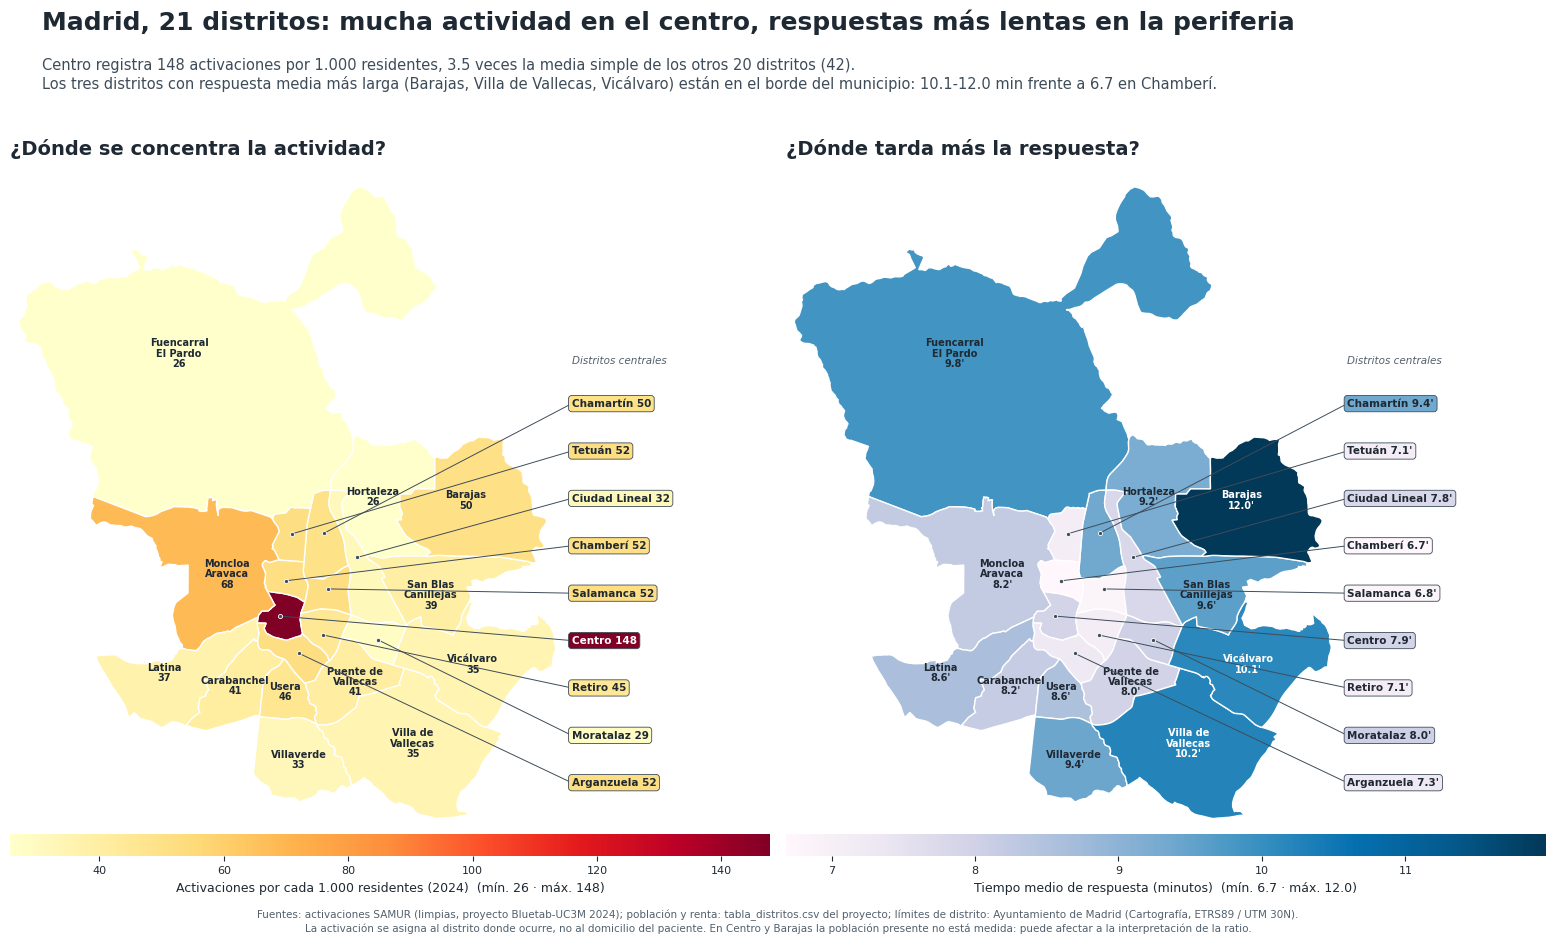

In [3]:
c1=plt.cm.YlOrRd; c2=plt.cm.PuBu
n1,col1,lab1,tc1=choro("activaciones_por_1000hab",c1,lambda v:f"{v:.0f}")
n2,col2,lab2,tc2=choro("tiempo_respuesta_medio_min",c2,lambda v:f"{v:.1f}'")
fig,axs=plt.subplots(1,2,figsize=(16,9.6),facecolor=BG)
draw(axs[0],col1,lab1,7,tc1,7.5);draw(axs[1],col2,lab2,7,tc2,7.5)
cbar(fig,axs[0],n1,c1,"Activaciones por cada 1.000 residentes (2024)");cbar(fig,axs[1],n2,c2,"Tiempo medio de respuesta (minutos)")
axs[0].set_title("¿Dónde se concentra la actividad?",fontsize=14,fontweight="bold",color=INK,loc="left")
axs[1].set_title("¿Dónde tarda más la respuesta?",fontsize=14,fontweight="bold",color=INK,loc="left")
top=t.nlargest(3,"activaciones_por_1000hab");slow=t.nlargest(3,"tiempo_respuesta_medio_min");fast=t.nsmallest(1,"tiempo_respuesta_medio_min").iloc[0]
tot=t.n_activaciones.sum()
fig.suptitle("Madrid, 21 distritos: mucha actividad en el centro, respuestas más lentas en la periferia",fontsize=18,fontweight="bold",color=INK,x=.04,ha="left",y=.975)
fig.text(.04,.925,f"Centro registra {top.iloc[0].activaciones_por_1000hab:.0f} activaciones por 1.000 residentes, {top.iloc[0].activaciones_por_1000hab/t[t.cod!=1].activaciones_por_1000hab.mean():.1f} veces la media simple de los otros 20 distritos ({t[t.cod!=1].activaciones_por_1000hab.mean():.0f}). "
 f"\nLos tres distritos con respuesta media más larga ({', '.join(slow.nombre)}) están en el borde del municipio: {slow.tiempo_respuesta_medio_min.min():.1f}-{slow.tiempo_respuesta_medio_min.max():.1f} min frente a {fast.tiempo_respuesta_medio_min:.1f} en {fast.nombre}.",
 fontsize=10.5,color="#3e4c59",ha="left",va="top")
foot(fig,"La activación se asigna al distrito donde ocurre, no al domicilio del paciente. En Centro y Barajas la población presente no está medida: puede afectar a la interpretación de la ratio.")
fig.subplots_adjust(left=.02,right=.98,top=.83,bottom=.09,wspace=.02)
fig.savefig("mapa_demanda_vs_respuesta.png",dpi=130,facecolor=BG);plt.show()


## 4. Mapa bivariante
Cada distrito va a su tercio de actividad y de tiempo de respuesta (7 distritos por tercio). Con 21 distritos la correlación es orientativa y no dice nada causal. Tampoco mide cobertura: no tenemos la ubicación exacta de las unidades.

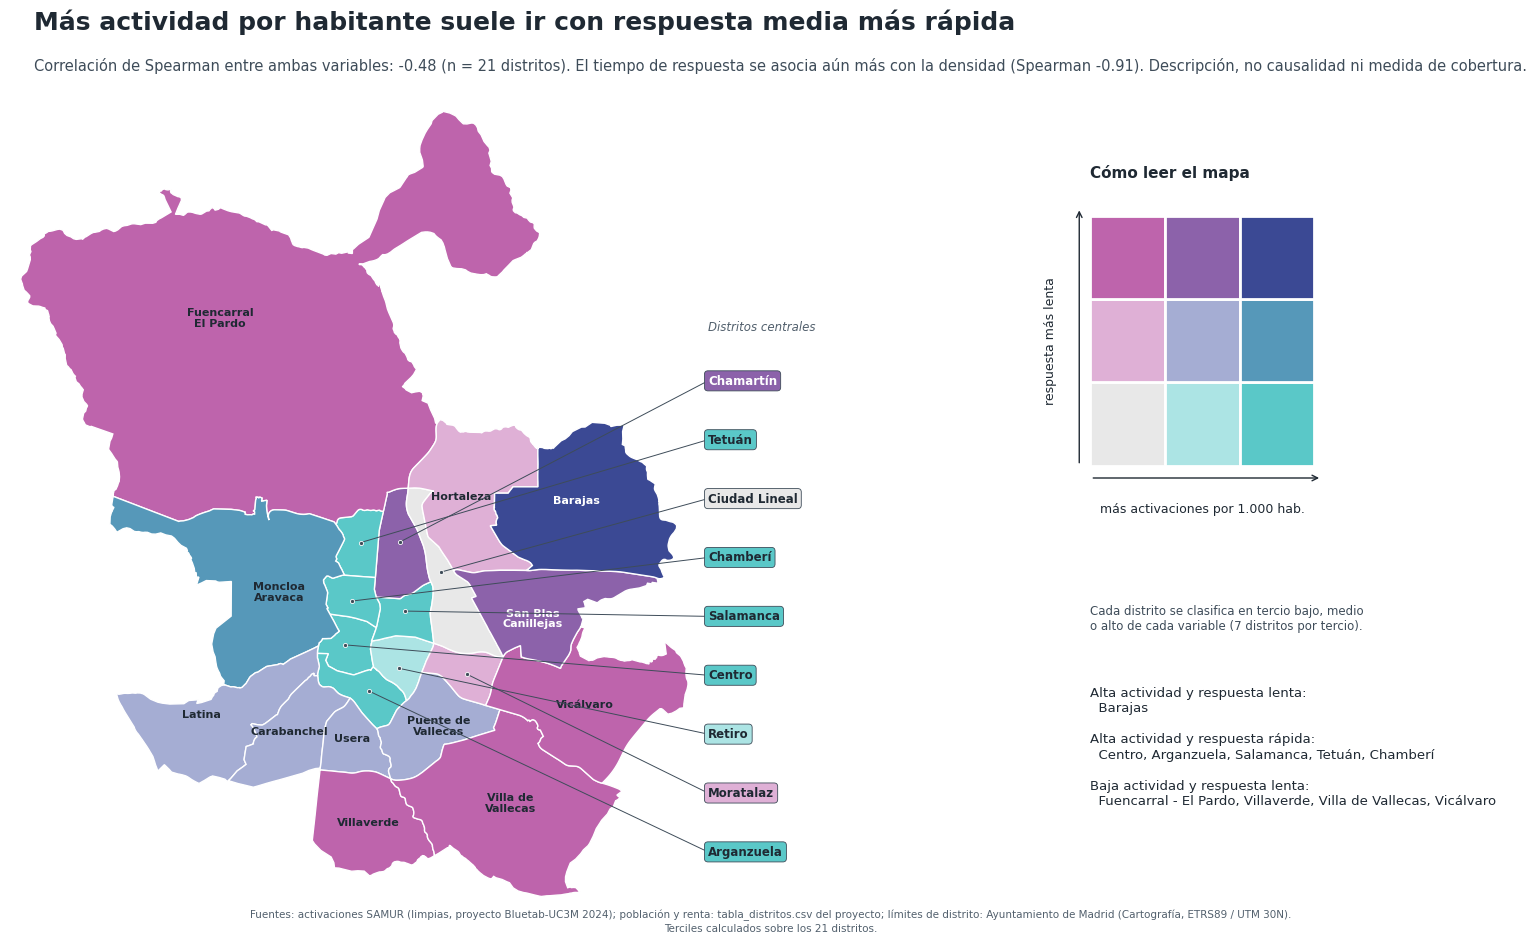

In [4]:
q=lambda s:pd.qcut(s,3,labels=False)
t["qa"]=q(t.activaciones_por_1000hab);t["qt"]=q(t.tiempo_respuesta_medio_min)
# bivariate palette (3x3), x=demand (cols), y=response time (rows)
pal=[["#e8e8e8","#ace4e4","#5ac8c8"],["#dfb0d6","#a5add3","#5698b9"],["#be64ac","#8c62aa","#3b4994"]]
colb={r.cod:pal[int(r.qt)][int(r.qa)] for _,r in t.iterrows()}
tcb={c:("white" if lum(colb[c])<.5 else INK) for c in colb}
labb={r.cod:r.lab for _,r in t.iterrows()}
fig=plt.figure(figsize=(16,9.6),facecolor=BG)
ax=fig.add_axes([.0,.04,.64,.84]);draw(ax,colb,labb,8,tcb,8.5)
# legend
lx=fig.add_axes([.70,.50,.14,.26]);lx.set_xlim(0,3);lx.set_ylim(0,3);lx.axis("off")
for i in range(3):
    for j in range(3): lx.add_patch(plt.Rectangle((j,i),1,1,fc=pal[i][j],ec="white",lw=2))
lx.annotate("",xy=(3.1,-.15),xytext=(0,-.15),arrowprops=dict(arrowstyle="->",color=INK),annotation_clip=False)
lx.annotate("",xy=(-.15,3.1),xytext=(-.15,0),arrowprops=dict(arrowstyle="->",color=INK),annotation_clip=False)
lx.text(1.5,-.45,"más activaciones por 1.000 hab.",ha="center",va="top",fontsize=9,color=INK)
lx.text(-.45,1.5,"respuesta más lenta",ha="right",va="center",rotation=90,fontsize=9,color=INK)
fig.text(.70,.80,"Cómo leer el mapa",fontsize=11,fontweight="bold",color=INK)
fig.text(.70,.355,"Cada distrito se clasifica en tercio bajo, medio\no alto de cada variable (7 distritos por tercio).",fontsize=8.5,color="#3e4c59",va="top")
hh=t[(t.qa==2)&(t.qt==2)].nombre.tolist();hl=t[(t.qa==2)&(t.qt==0)].nombre.tolist();lh=t[(t.qa==0)&(t.qt==2)].nombre.tolist()
txt=("Alta actividad y respuesta lenta:\n  "+(", ".join(hh) or "ninguno")+"\n\nAlta actividad y respuesta rápida:\n  "+(", ".join(hl) or "ninguno")+"\n\nBaja actividad y respuesta lenta:\n  "+(", ".join(lh) or "ninguno"))
fig.text(.70,.27,txt,fontsize=9.5,color=INK,va="top",linespacing=1.25)
rho=t[["activaciones_por_1000hab","tiempo_respuesta_medio_min"]].corr(method="spearman").iloc[0,1]
fig.text(.04,.975,"Más actividad por habitante suele ir con respuesta media más rápida",fontsize=18,fontweight="bold",color=INK,va="top")
rd=t[["densidad_hab_km2","tiempo_respuesta_medio_min"]].corr(method="spearman").iloc[0,1]
fig.text(.04,.925,f"Correlación de Spearman entre ambas variables: {rho:+.2f} (n = 21 distritos). El tiempo de respuesta se asocia aún más con la densidad (Spearman {rd:+.2f}). Descripción, no causalidad ni medida de cobertura.",fontsize=10.5,color="#3e4c59",va="top")
foot(fig,"Terciles calculados sobre los 21 distritos.")
fig.savefig("mapa_bivariante_demanda_respuesta.png",dpi=130,facecolor=BG);plt.show()


## 5. Contexto social
Renta, vulnerabilidad y población mayor de 65 años para situar los distritos. Los 6 valores marcados con * están imputados (en los datos originales faltaban 10 huecos; se rellenaron con la media de los 3 distritos más parecidos, como indica el README del proyecto).

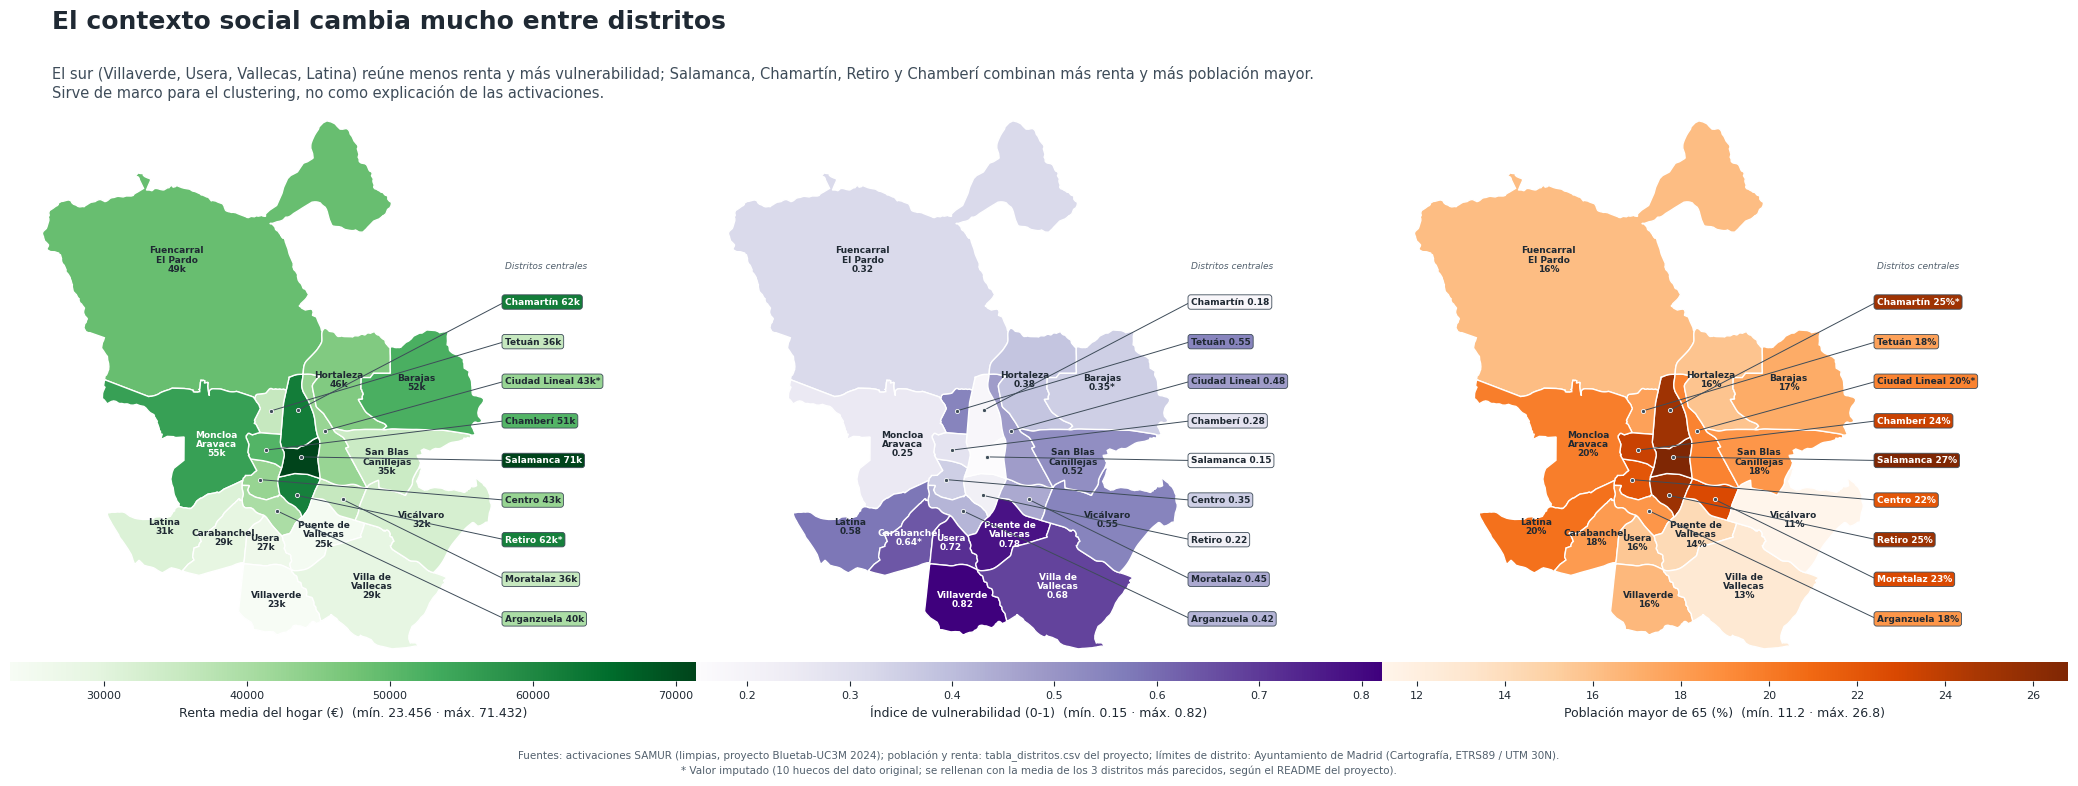

In [5]:
vars_=[("renta_media_hogar",plt.cm.Greens,lambda v:f"{v/1000:.0f}k","Renta media del hogar (€)"),
       ("indice_vulnerabilidad",plt.cm.Purples,lambda v:f"{v:.2f}","Índice de vulnerabilidad (0-1)"),
       ("pct_mayores_65",plt.cm.Oranges,lambda v:f"{v:.0f}%","Población mayor de 65 (%)")]
fig,axs=plt.subplots(1,3,figsize=(21,8),facecolor=BG)
for ax,(v,cmap,f,l) in zip(axs,vars_):
    n,col,lab,tc=choro(v,cmap,f);draw(ax,col,lab,6.5,tc,6.5);cbar(fig,ax,n,cmap,l)
fig.suptitle("El contexto social cambia mucho entre distritos",fontsize=18,fontweight="bold",color=INK,x=.03,ha="left",y=.97)
fig.text(.03,.90,"El sur (Villaverde, Usera, Vallecas, Latina) reúne menos renta y más vulnerabilidad; Salamanca, Chamartín, Retiro y Chamberí combinan más renta y más población mayor.\nSirve de marco para el clustering, no como explicación de las activaciones.",fontsize=10.5,color="#3e4c59",va="top")
foot(fig,"* Valor imputado (10 huecos del dato original; se rellenan con la media de los 3 distritos más parecidos, según el README del proyecto).")
fig.subplots_adjust(left=.01,right=.99,top=.84,bottom=.13,wspace=.0)
fig.savefig("mapa_contexto_social.png",dpi=120,facecolor=BG);plt.show()


## Límites
- n = 21 distritos: las correlaciones son descriptivas.
- El denominador es población residente, no población presente.
- El tiempo de respuesta medio no es cobertura ni calidad del servicio.
- No hay ubicación exacta de las emergencias, por eso no hay puntos en el mapa.